# 🩺 MedMonitor — Monitoramento Multimodal de Pacientes

**Tech Challenge · Fase 4 · Pós-Tech IA para Devs (FIAP)**

Este notebook executa a solução passo a passo, modalidade por modalidade, até a fusão e os alertas à equipe médica:

| Seção | Conteúdo |
|---|---|
| 1 | Configuração do ambiente (Colab ou VS Code) |
| 2 | Credenciais Azure (opcional) |
| 3 | Sinais vitais — NEWS2 + z-score robusto + Isolation Forest |
| 4 | Monitor em tempo real (streaming) |
| 5 | Prescrições |
| 6 | Movimentação no leito |
| 7 | Áudio — Azure Speech to Text, Azure Text Analytics e biomarcadores vocais |
| 8 | Vídeo — YOLOv8-pose / OpenPose e YOLOv8 |
| 9 | Dados reais — PhysioNet BIDMC |
| 10 | Fusão multimodal e alertas |

Funciona no **Google Colab** (*Ambiente de execução → Executar tudo*) e no **VS Code** (selecione o kernel do `.venv` do projeto).

## 1. Configuração do ambiente

In [ ]:
import os, sys, subprocess, zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# Como obter o código no Colab — escolha UMA opção:
#   "upload" → envie o arquivo colab/medmonitor.zip quando o seletor aparecer
#   "drive"  → coloque medmonitor.zip em MyDrive/ e ajuste DRIVE_ZIP
#   "github" → informe a URL do repositório em GITHUB_URL
FONTE = "upload"
DRIVE_ZIP = "/content/drive/MyDrive/medmonitor.zip"
GITHUB_URL = ""

if IN_COLAB:
    ROOT = Path("/content/medmonitor")
    if not (ROOT / "src" / "medmonitor").exists():
        if FONTE == "github":
            subprocess.run(["git", "clone", "-q", GITHUB_URL, str(ROOT)], check=True)
        else:
            if FONTE == "drive":
                from google.colab import drive
                drive.mount("/content/drive")
                zip_path = DRIVE_ZIP
            else:
                from google.colab import files
                zip_path = next(iter(files.upload()))
            ROOT.mkdir(parents=True, exist_ok=True)
            zipfile.ZipFile(zip_path).extractall(ROOT)
else:
    # VS Code / Jupyter local: o notebook fica em <projeto>/colab/
    ROOT = Path.cwd().parent if (Path.cwd().parent / "src" / "medmonitor").exists() else Path.cwd()

os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
print("Ambiente:", "Google Colab" if IN_COLAB else "local (VS Code)", "| projeto:", ROOT)

In [ ]:
# Dependências: no Colab instala o que falta (PyTorch já vem instalado); localmente use o .venv do projeto
if IN_COLAB:
    subprocess.run("apt-get -qq install -y ffmpeg > /dev/null", shell=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics", "opencv-python-headless<5",
                    "opencv-python<5", "librosa", "soundfile", "wfdb", "gTTS", "python-dotenv", "pyyaml",
                    "azure-cognitiveservices-speech", "azure-ai-textanalytics"], check=True)

import warnings
warnings.filterwarnings("ignore")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, HTML, Image, Markdown, display

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.figsize": (12, 3), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#ecebe8"})
import torch
print("GPU disponível:", torch.cuda.is_available())

GPU disponível: False


## 2. Credenciais Azure (opcional)

Sem credenciais, tudo funciona em **modo local** (transcrição de referência + léxico em português) e cada resultado indica a fonte usada.

- **Colab:** cadastre em 🔑 *Secrets* (barra lateral) `AZURE_SPEECH_KEY`, `AZURE_SPEECH_REGION`, `AZURE_LANGUAGE_KEY`, `AZURE_LANGUAGE_ENDPOINT` e habilite o acesso do notebook.
- **VS Code:** preencha o arquivo `.env` na raiz do projeto (ou rode `bash infra/azure_setup.sh`).

In [ ]:
AZ_VARS = ["AZURE_SPEECH_KEY", "AZURE_SPEECH_REGION", "AZURE_LANGUAGE_KEY", "AZURE_LANGUAGE_ENDPOINT"]
if IN_COLAB:
    from google.colab import userdata
    for k in AZ_VARS:
        try:
            os.environ[k] = userdata.get(k) or ""
        except Exception:
            pass

from medmonitor.config import load_config, azure_speech_enabled, azure_language_enabled
load_config.cache_clear()
cfg = load_config()
cfg["alerts"]["console"] = False
print("Azure Speech:  ", "ATIVO" if azure_speech_enabled(cfg) else "fallback local")
print("Azure Language:", "ATIVO" if azure_language_enabled(cfg) else "fallback local")

Azure Speech:   fallback local
Azure Language: fallback local


## 3. Sinais vitais

Cinco pacientes sintéticos (24 h, uma amostra por minuto), cada um com um cenário clínico e anomalias **rotuladas** (*ground truth*) para medir o desempenho. Três detectores votam; uma anomalia é confirmada com **2 de 3 votos e persistência mínima de 3 minutos**.

In [ ]:
from medmonitor.data import synthetic
from medmonitor.anomaly.vitals import detect_vitals_anomalies, VITAL_NAMES, VITAL_UNITS
from medmonitor.anomaly.utils import event_overlap_metrics

vitals = synthetic.generate_vitals()
display(pd.DataFrame.from_dict(synthetic.PATIENTS, orient="index"))
vitals.head()

,nome,idade,leito,cenario
P001,Ana Souza,54,UTI-01,Controle estável
P002,Bruno Lima,71,UTI-02,Sepse de foco pulmonar
P003,Carla Mendes,63,ENF-12,Pós-operatório abdominal em analgesia com opioide
P004,Diego Rocha,68,UCO-03,Fibrilação atrial paroxística
P005,Elisa Prado,79,ENF-07,Pós-operatório de artroplastia de quadril


,timestamp,patient_id,hr,sbp,dbp,spo2,rr,temp,anomaly_type
0,2026-10-28 08:00:00,P001,71,119,74,97,16,36.6,
1,2026-10-28 08:01:00,P001,71,118,74,98,15,36.6,
2,2026-10-28 08:02:00,P001,71,118,73,98,15,36.5,
3,2026-10-28 08:03:00,P001,70,119,73,98,15,36.5,
4,2026-10-28 08:04:00,P001,70,117,74,98,15,36.5,


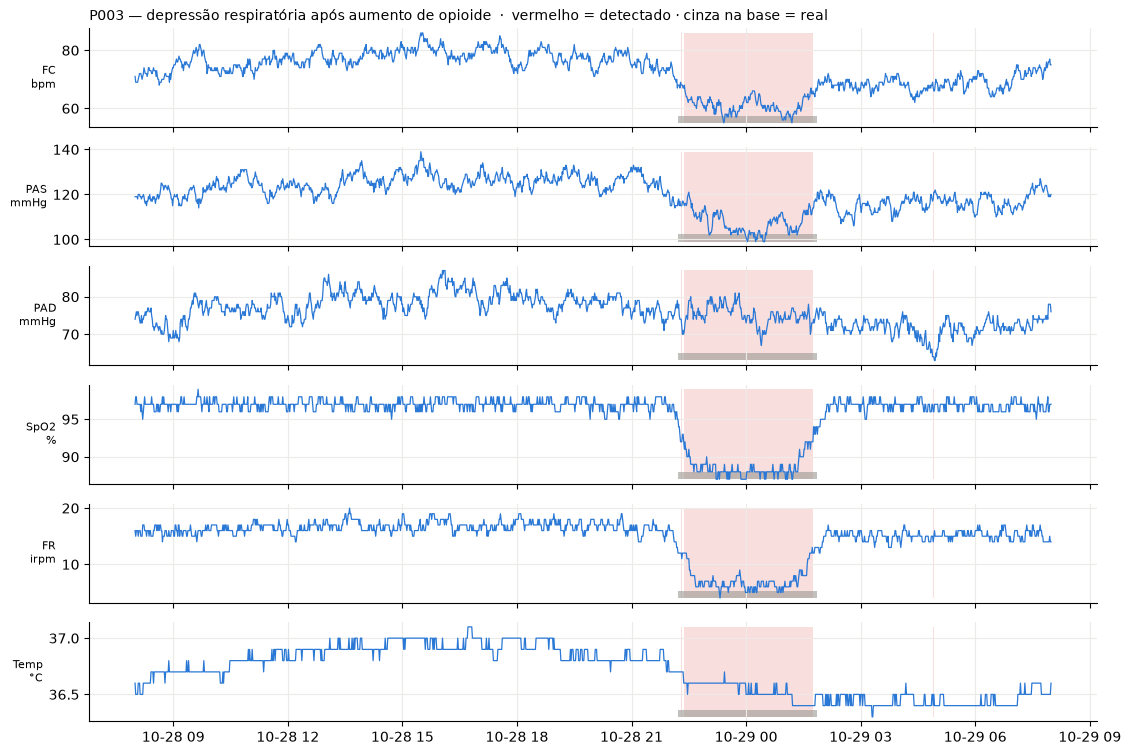

In [5]:
def plot_vitals(frame, title):
    cols = [c for c in VITAL_NAMES if c in frame]
    fig, axes = plt.subplots(len(cols), 1, figsize=(13, 1.5 * len(cols)), sharex=True)
    truth = frame.get("anomaly_type", pd.Series([""] * len(frame))).replace("artifact", "") != ""
    for ax, c in zip(axes, cols):
        ax.plot(frame["timestamp"], frame[c], color="#2a78d6", lw=0.9)
        ymin, ymax = frame[c].min(), frame[c].max()
        ax.fill_between(frame["timestamp"], ymin, ymax, where=frame["anomaly"], color="#e34948", alpha=0.18, lw=0)
        ax.fill_between(frame["timestamp"], ymin, ymin + 0.08 * (ymax - ymin), where=truth, color="#9a9893", alpha=0.6, lw=0)
        ax.set_ylabel(f"{VITAL_NAMES[c]}\n{VITAL_UNITS[c]}", rotation=0, ha="right", va="center", fontsize=8)
    axes[0].set_title(title + "  ·  vermelho = detectado · cinza na base = real", loc="left", fontsize=10)
    plt.show()

results_vitals = {}
for pid, g in vitals.groupby("patient_id"):
    results_vitals[pid] = detect_vitals_anomalies(g, cfg)

plot_vitals(results_vitals["P003"].frame, "P003 — depressão respiratória após aumento de opioide")

In [6]:
# Alertas de sinais vitais de todos os pacientes
pd.DataFrame([{"paciente": a.patient_id, "horário": a.timestamp[5:16], "severidade": a.severity.name,
               "alerta": a.title, "descrição": a.description}
              for r in results_vitals.values() for a in r.alerts])

,paciente,horário,severidade,alerta,descrição
0,P002,10-28T18:18,CRITICAL,Taquicardia + Hipotensão + Taquipneia + Febre,FC 118.0 bpm (basal 73.0); PAS 72.0 mmHg (basal 122.0); FR 25.0 irpm (basal 16.0); Temp 39.2 °C (basal 36.7). NEWS2 ...
1,P003,10-28T22:17,CRITICAL,Bradicardia + Hipotensão + Dessaturação + Bradipneia,FC 55.0 bpm (basal 74.0); PAS 99.0 mmHg (basal 122.0); SpO2 87.0 % (basal 97.0); FR 4.0 irpm (basal 16.0). NEWS2 máx...
2,P003,10-29T04:53,INFO,Hipotensão diastólica,"PAD 64.0 mmHg (basal 76.0). NEWS2 máx. 0 (risco baixo), duração 3.0 min."
3,P004,10-28T11:02,WARNING,Taquicardia,"FC 164.0 bpm (basal 74.0). NEWS2 máx. 3 (risco baixo-médio), duração 28.0 min."
4,P004,10-28T14:19,INFO,Taquicardia,"FC 88.0 bpm (basal 74.0). NEWS2 máx. 0 (risco baixo), duração 4.0 min."
5,P004,10-28T19:22,WARNING,Taquicardia,"FC 169.0 bpm (basal 74.0). NEWS2 máx. 3 (risco baixo-médio), duração 41.0 min."
6,P004,10-29T02:04,WARNING,Taquicardia,"FC 159.0 bpm (basal 74.0). NEWS2 máx. 4 (risco baixo-médio), duração 30.0 min."
7,P004,10-29T05:10,WARNING,Bradicardia,"FC 38.0 bpm (basal 74.0). NEWS2 máx. 3 (risco baixo-médio), duração 17.0 min."
8,P005,10-28T14:58,WARNING,Dessaturação + Taquipneia + Febre,"SpO2 91.0 % (basal 97.0); FR 23.0 irpm (basal 16.0); Temp 37.7 °C (basal 36.7). NEWS2 máx. 5 (risco médio), duração ..."
9,P005,10-29T03:03,WARNING,Taquicardia + Hipertensão + Taquipneia,"FC 104.0 bpm (basal 73.0); PAS 143.0 mmHg (basal 121.0); FR 22.0 irpm (basal 16.0). NEWS2 máx. 3 (risco baixo), dura..."


In [7]:
# Avaliação por evento: cada detector isolado × ensemble
methods = {"Regras clínicas (NEWS2)": "flag_rules", "z-score robusto": "flag_zscore",
           "Isolation Forest": "flag_iforest", "Ensemble": "anomaly"}
rows = []
for name, col in methods.items():
    tot = {"reais": 0, "detectados": 0, "previstos": 0, "previstos_ok": 0}
    for pid, r in results_vitals.items():
        truth = (r.frame["anomaly_type"].replace("artifact", "") != "").to_numpy()
        m = event_overlap_metrics(r.frame[col].to_numpy(), truth, merge_gap=cfg["vitals"]["merge_gap"])
        tot["reais"] += m["eventos_reais"]; tot["detectados"] += m["eventos_detectados"]
        tot["previstos"] += m["eventos_previstos"]
        tot["previstos_ok"] += round((m["precisao_evento"] or 0) * m["eventos_previstos"])
    rec, prec = tot["detectados"] / tot["reais"], tot["previstos_ok"] / tot["previstos"]
    rows.append({"método": name, "recall": round(rec, 3), "precisão": round(prec, 3),
                 "F1": round(2 * rec * prec / (rec + prec), 3)})
pd.DataFrame(rows)

,método,recall,precisão,F1
0,Regras clínicas (NEWS2),0.875,0.889,0.882
1,z-score robusto,1.000,0.533,0.696
2,Isolation Forest,1.000,0.211,0.348
3,Ensemble,1.000,0.800,0.889


O paciente **P001** (controle) contém um artefato de oxímetro (SpO2 = 62% por 1 minuto). A persistência mínima o filtra:

In [8]:
f = results_vitals["P001"].frame
print("Artefato presente:", (f["anomaly_type"] == "artifact").any(),
      "| marcado como anomalia:", bool(f.loc[f["anomaly_type"] == "artifact", "anomaly"].any()),
      "| alertas do P001:", len(results_vitals["P001"].alerts))

Artefato presente: True | marcado como anomalia: False | alertas do P001: 0


## 4. Monitor em tempo real

O `StreamingVitalsMonitor` recebe **uma amostra por vez** (como viria do monitor multiparamétrico) e emite o alerta no momento em que a anomalia se confirma.

In [9]:
from medmonitor.anomaly.vitals import StreamingVitalsMonitor, news2_score
from medmonitor.alerts import AlertManager

g = vitals[vitals.patient_id == "P003"].reset_index(drop=True)
mon = StreamingVitalsMonitor("P003", cfg)
mgr = AlertManager(cfg)  # aplica o cooldown de 30 min contra repetições
for row in g.to_dict(orient="records"):
    alerts = [a for a in mon.update(row) if mgr.dispatch(a)]
    t = pd.Timestamp(row["timestamp"])
    if t.minute == 0 and 21 <= t.hour <= 23:
        print(f"{t:%H:%M}  FC {row['hr']:>3}  SpO2 {row['spo2']}%  FR {row['rr']:>2}  NEWS2 {news2_score(row)[0]}")
    for a in alerts:
        print(f"   🔔 {a.timestamp[11:16]} [{a.severity.name}] {a.title} — {a.description}")

21:00  FC  75  SpO2 97%  FR 17  NEWS2 0
22:00  FC  74  SpO2 97%  FR 16  NEWS2 0
   🔔 22:19 [WARNING] Dessaturação — SpO2 = 92.0 % por 3 amostras consecutivas. NEWS2 atual 3.
   🔔 22:33 [WARNING] Bradipneia — FR = 8.0 irpm por 3 amostras consecutivas. NEWS2 atual 6.
   🔔 22:35 [WARNING] NEWS2 elevado (6) — Escore NEWS2 6 (risco médio).
   🔔 22:38 [WARNING] Bradicardia — FC = 62.0 bpm por 3 amostras consecutivas. NEWS2 atual 6.
23:00  FC  63  SpO2 88%  FR  7  NEWS2 7
   🔔 23:03 [CRITICAL] Hipotensão — PAS = 102.0 mmHg por 3 amostras consecutivas. NEWS2 atual 7.
   🔔 23:08 [WARNING] Bradicardia — FC = 60.0 bpm por 3 amostras consecutivas. NEWS2 atual 6.
   🔔 23:38 [CRITICAL] Hipotensão — PAS = 103.0 mmHg por 3 amostras consecutivas. NEWS2 atual 7.
   🔔 00:03 [CRITICAL] Bradicardia — FC = 62.0 bpm por 3 amostras consecutivas. NEWS2 atual 8.


   🔔 01:08 [CRITICAL] Hipotensão — PAS = 102.0 mmHg por 3 amostras consecutivas. NEWS2 atual 7.
   🔔 04:55 [WARNING] Hipotensão diastólica — PAD = 64.0 mmHg por 3 amostras consecutivas. NEWS2 atual 0.


## 5. Prescrições — alterações inesperadas no tratamento

In [10]:
from medmonitor.anomaly.prescriptions import detect_prescription_anomalies

rx = detect_prescription_anomalies(synthetic.generate_prescriptions(), cfg)
view = rx.frame[["patient_id", "timestamp", "drug", "dose", "unit", "frequency_per_day", "dose_ratio",
                 "high_alert", "findings", "anomaly", "expected_anomaly"]]
display(view.style.apply(lambda r: ["background-color:#fbe4e4" if r["anomaly"] else ""] * len(r), axis=1))
print("Acerto (detectado == esperado):", (rx.frame["anomaly"] == rx.frame["expected_anomaly"]).mean())

,patient_id,timestamp,drug,dose,unit,frequency_per_day,dose_ratio,high_alert,findings,anomaly,expected_anomaly
0,P001,2026-10-28 08:30:00,dipirona,1000,mg,4,1.000000,False,[],False,False
1,P001,2026-10-28 08:30:00,enoxaparina,40,mg,1,1.000000,True,[],False,False
2,P001,2026-10-28 14:00:00,paracetamol,750,mg,4,1.000000,False,[],False,False
3,P001,2026-10-28 20:00:00,dipirona,1000,mg,3,0.750000,False,[],False,False
4,P002,2026-10-28 08:15:00,dipirona,1000,mg,4,1.000000,False,[],False,False
5,P002,2026-10-28 10:00:00,enoxaparina,40,mg,1,1.000000,True,[],False,False
6,P002,2026-10-28 18:30:00,vancomicina,1000,mg,2,1.000000,False,[],False,False
7,P002,2026-10-28 19:00:00,heparina,5000,UI,3,1.000000,True,"['duplicidade terapêutica (anticoagulante: heparina + enoxaparina)', 'interação potencial heparina × enoxaparina']",True,True
8,P002,2026-10-29 00:00:00,vancomicina,2000,mg,2,2.000000,False,"['alteração abrupta de dose (2000 → 4000 mg/dia, 2.0x)']",True,True
9,P003,2026-10-28 08:00:00,morfina,2,mg,6,1.000000,True,[],False,False


Acerto (detectado == esperado): 1.0


## 6. Movimentação no leito — imobilidade, agitação noturna e queda

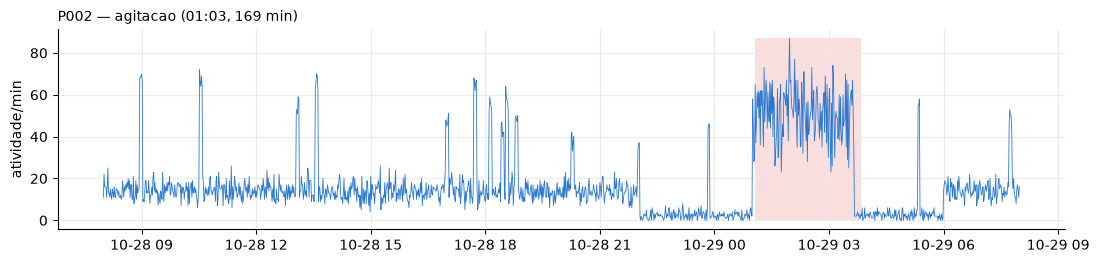

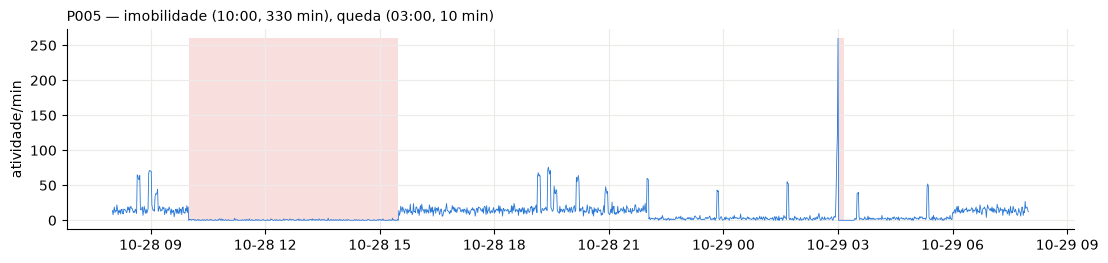

In [11]:
from medmonitor.anomaly.movement import detect_movement_anomalies

movement = synthetic.generate_movement()
results_mov = {pid: detect_movement_anomalies(g, cfg) for pid, g in movement.groupby("patient_id")}
for pid in ("P002", "P005"):
    r = results_mov[pid]
    fig, ax = plt.subplots(figsize=(13, 2.6))
    ax.plot(r.frame["timestamp"], r.frame["activity"], color="#2a78d6", lw=0.6)
    ax.fill_between(r.frame["timestamp"], 0, r.frame["activity"].max(), where=r.frame["anomaly"], color="#e34948", alpha=0.18, lw=0)
    ax.set_title(f"{pid} — " + ", ".join(f"{e['type']} ({e['start_ts'][11:16]}, {e['minutes']} min)" for e in r.events), loc="left", fontsize=10)
    ax.set_ylabel("atividade/min")
    plt.show()

## 7. Áudio das consultas

1. **Biomarcadores vocais** (librosa): ritmo, pausas, F0, jitter/shimmer, inspirações audíveis, tremor vocal → indicadores de **fadiga**, **dificuldade respiratória** e **disartria**.
2. **Azure Speech to Text**: transcrição contínua em pt-BR com timestamps por palavra.
3. **Azure Text Analytics**: sentimento, frases-chave, entidades de saúde, termos críticos com negação.

Os áudios de demonstração são fala sintetizada com efeitos que simulam cada condição.

In [12]:
from medmonitor.pipeline import ensure_audio
from medmonitor.audio.analyzer import analyze_audio

manifest = ensure_audio(cfg)
audio_meta = pd.read_csv(manifest)
audio_results = {}
for _, row in audio_meta.iterrows():
    audio_results[row["file"]] = analyze_audio(manifest.parent / row["file"], cfg, row["patient_id"], row["timestamp"])

pd.DataFrame([{"arquivo": f, "esperado": audio_meta.set_index("file").loc[f, "expected_condition"],
               **{k: v for k, v in r.indicators.items() if not k.startswith("_")},
               "fonte transcrição": r.transcript["source"], "fonte texto": r.text_analysis["source"]}
              for f, r in audio_results.items()])

,arquivo,esperado,fadiga,dificuldade_respiratoria,disartria,fonte transcrição,fonte texto
0,P001_consulta_normal.wav,normal,0.07,0.01,0.02,sidecar,local
1,P003_consulta_dispneia.wav,dispneia,0.22,0.82,0.45,sidecar,local
2,P004_consulta_disartria.wav,disartria,0.37,0.00,0.60,sidecar,local
3,P005_consulta_fadiga.wav,fadiga,0.75,0.00,0.23,sidecar,local


Transcrição: Doutor, eu estou com falta de ar. Parece que o ar não entra direito. Estou muito sonolenta, e sinto um cansaço para respirar. Me deram um remédio para dor mais forte, e depois disso piorou.
Sentimento: negative {'positive': 0.0, 'neutral': 0.25, 'negative': 0.75}
Termos críticos: [('falta de ar', 'respiratorio'), ('cansaço para respirar', 'respiratorio')]


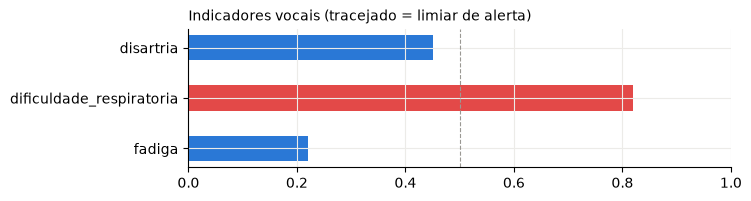

🔔 [CRITICAL] Padrão de fala sugestivo de dificuldade respiratória — Indicador vocal 0.82 (0-1). Corroborado pelo relato do paciente: cansaço para respirar, falta de ar.
🔔 [WARNING] Sintomas críticos relatados na consulta — Termos identificados na transcrição: cansaço para respirar, falta de ar.


In [13]:
ARQUIVO = "P003_consulta_dispneia.wav"   # troque para ouvir/analisar outro
r = audio_results[ARQUIVO]
display(Audio(str(manifest.parent / ARQUIVO)))
print("Transcrição:", r.transcript["text"])
print("Sentimento:", r.text_analysis["sentiment"]["label"], r.text_analysis["sentiment"]["scores"])
print("Termos críticos:", [(t["term"], "negado" if t["negated"] else t["category"]) for t in r.text_analysis["critical_terms"]])
ind = {k: v for k, v in r.indicators.items() if not k.startswith("_")}
fig, ax = plt.subplots(figsize=(7, 1.8))
ax.barh(list(ind), list(ind.values()), color=["#e34948" if v >= 0.5 else "#2a78d6" for v in ind.values()], height=0.5)
ax.axvline(0.5, color="#9a9893", ls="--", lw=0.8); ax.set_xlim(0, 1)
ax.set_title("Indicadores vocais (tracejado = limiar de alerta)", loc="left", fontsize=10)
plt.show()
for a in r.alerts:
    print(f"🔔 [{a.severity.name}] {a.title} — {a.description}")

Para analisar um áudio seu (wav/mp3/m4a), informe o caminho:

In [14]:
MEU_AUDIO = ""   # ex.: "/content/minha_consulta.m4a" (no Colab, envie pelo painel de arquivos)
if MEU_AUDIO:
    res = analyze_audio(MEU_AUDIO, cfg, "teste")
    display(Audio(MEU_AUDIO)); print(res.transcript["text"]); print(res.indicators)
    for a in res.alerts: print(f"🔔 [{a.severity.name}] {a.title} — {a.description}")

## 8. Vídeo — pose (YOLOv8-pose / OpenPose) e objetos (YOLOv8)

Cada vídeo gera: vídeo anotado, gráfico de ângulos, repetições e eventos (repetição incompleta, compensação de tronco, assimetria, **queda**, área crítica...). Com GPU no Colab o processamento é bem mais rápido.

In [15]:
from medmonitor.pipeline import ensure_video
from medmonitor.video.analyzer import VideoAnalyzer
from base64 import b64encode

vmanifest = ensure_video(cfg)
video_meta = pd.read_csv(vmanifest, keep_default_na=False)
display(video_meta[["file", "patient_id", "profile", "description", "source"]])

analyzer = VideoAnalyzer(cfg)

def show_video(path, width=640):
    data = b64encode(Path(path).read_bytes()).decode()
    display(HTML(f'<video width="{width}" controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>'))

def run_video(file):
    row = video_meta.set_index("file").loc[file]
    res = analyzer.analyze(vmanifest.parent / file, row["patient_id"], row["profile"] or None, ROOT / "outputs" / "video",
                           row["timestamp"], row["target"], use_zones=str(row["zones"]) == "True")
    print(json.dumps(res.summary, ensure_ascii=False, default=str))
    for a in res.alerts:
        print(f"🔔 [{a.severity.name}] {a.title} — {a.description}")
    display(Image(res.plot_path, width=900))
    show_video(res.annotated_path)
    return res

,file,patient_id,profile,description,source
0,P005_sentar_levantar.mp4,P005,sentar_levantar,Teste de sentar e levantar 30 s,CDC STEADI — domínio público
1,P001_agachamento.mp4,P001,agachamento,Sessão de fisioterapia — agachamento,Taco fleur — CC BY-SA 4.0 (Wikimedia Commons)
2,P005_queda_simulada.mp4,P005,,Queda simulada (rotação sintética),Derivado de Taco fleur — CC BY-SA 4.0
3,zona_critica.mp4,SALA-01,,Circulação em área crítica,Ultralytics assets — AGPL-3.0


{"pessoa_visivel_pct": 100.0, "max_pessoas_quadro": 1, "repeticoes": 6, "repeticoes_incompletas": 0, "amplitude_media": 107.6, "angulo_minimo_medio": 51.9, "cadencia_s_por_rep": 2.87, "tendencia_amplitude_graus_por_rep": -0.65, "eventos": 1}
🔔 [WARNING] Compensação de tronco — inclinação máx. 56° (limite 45°) — trecho 9.4s a 9.9s de P001_agachamento.mp4.


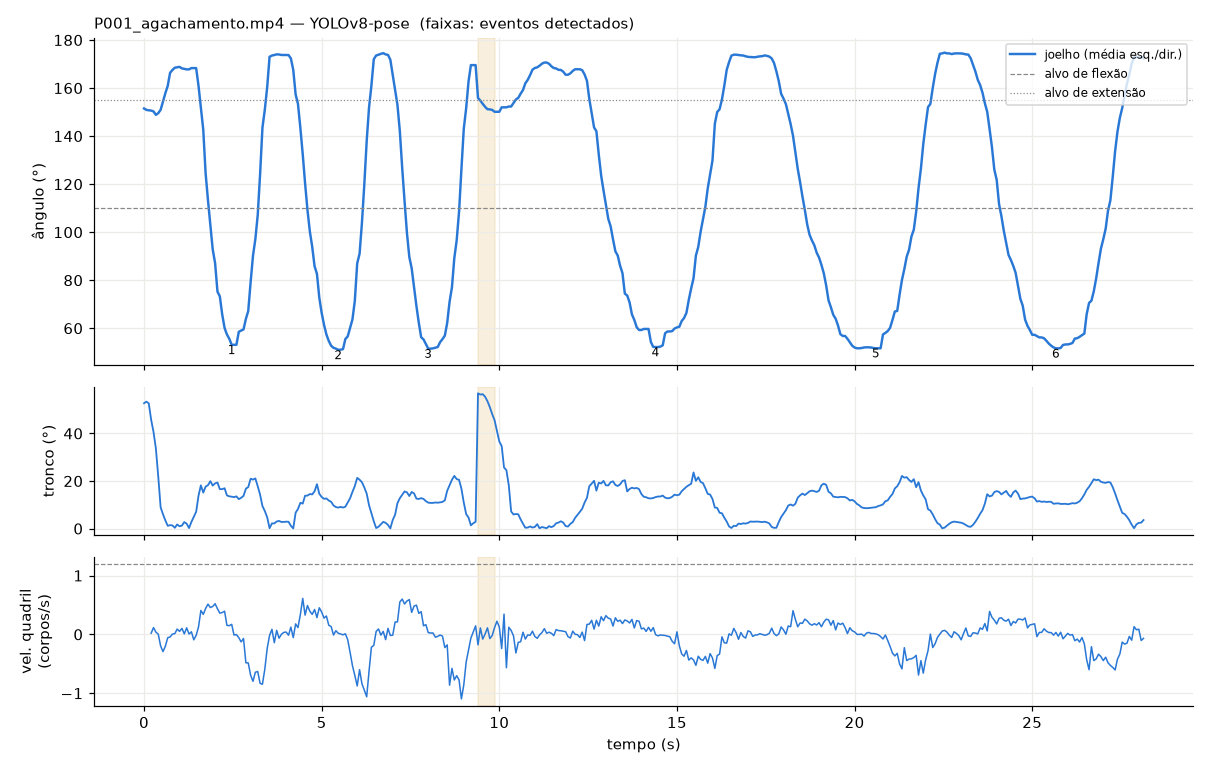

,rep,start_s,bottom_s,end_s,min_angle,max_angle,rom,duration_s
0,1,1.60,2.47,3.47,53.1,160.5,107.4,1.87
1,2,4.33,5.47,6.40,51.0,161.1,110.0,2.07
2,3,7.13,8.00,9.13,51.5,162.7,111.1,2.00
3,4,12.60,14.40,16.27,52.2,155.3,103.1,3.67
4,5,18.20,20.60,22.20,51.7,160.0,108.4,4.00
5,6,23.73,25.67,27.60,51.6,157.0,105.4,3.87


In [16]:
res_squat = run_video("P001_agachamento.mp4")
pd.DataFrame(res_squat.reps)

{"pessoa_visivel_pct": 100.0, "max_pessoas_quadro": 1, "eventos": 1}
🔔 [CRITICAL] Queda detectada — velocidade do quadril 2.4 corpos/s — trecho 7.3s a 8.8s de P005_queda_simulada.mp4.


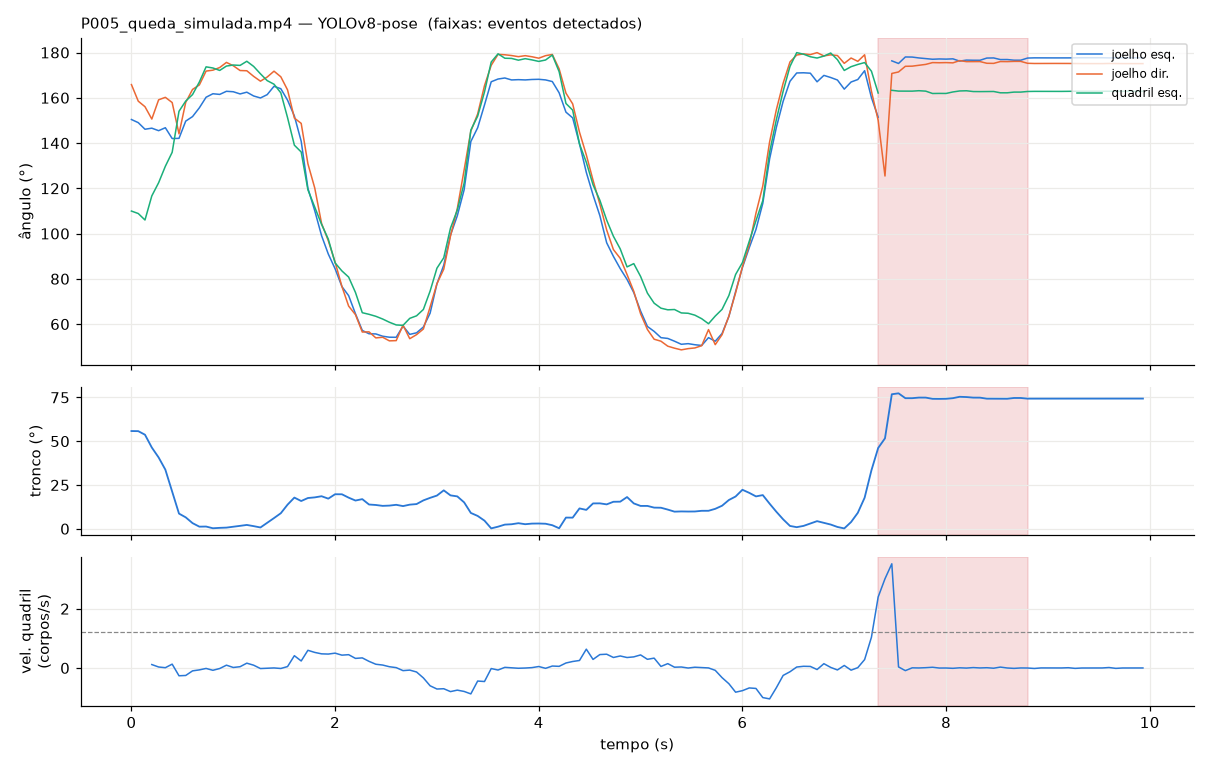

In [17]:
res_fall = run_video("P005_queda_simulada.mp4")   # queda SIMULADA (rotação sintética) para validar o detector

{"pessoa_visivel_pct": 100.0, "max_pessoas_quadro": 7, "eventos": 4}
🔔 [WARNING] Lotação acima do limite em área crítica — 6 pessoas em area_restrita — trecho 0.8s a 2.0s de zona_critica.mp4.
🔔 [WARNING] Lotação acima do limite em área crítica — 6 pessoas em area_restrita — trecho 2.9s a 4.2s de zona_critica.mp4.
🔔 [WARNING] Lotação acima do limite em área crítica — 5 pessoas em area_restrita — trecho 4.9s a 6.1s de zona_critica.mp4.
🔔 [WARNING] Lotação acima do limite em área crítica — 6 pessoas em area_restrita — trecho 6.9s a 8.2s de zona_critica.mp4.


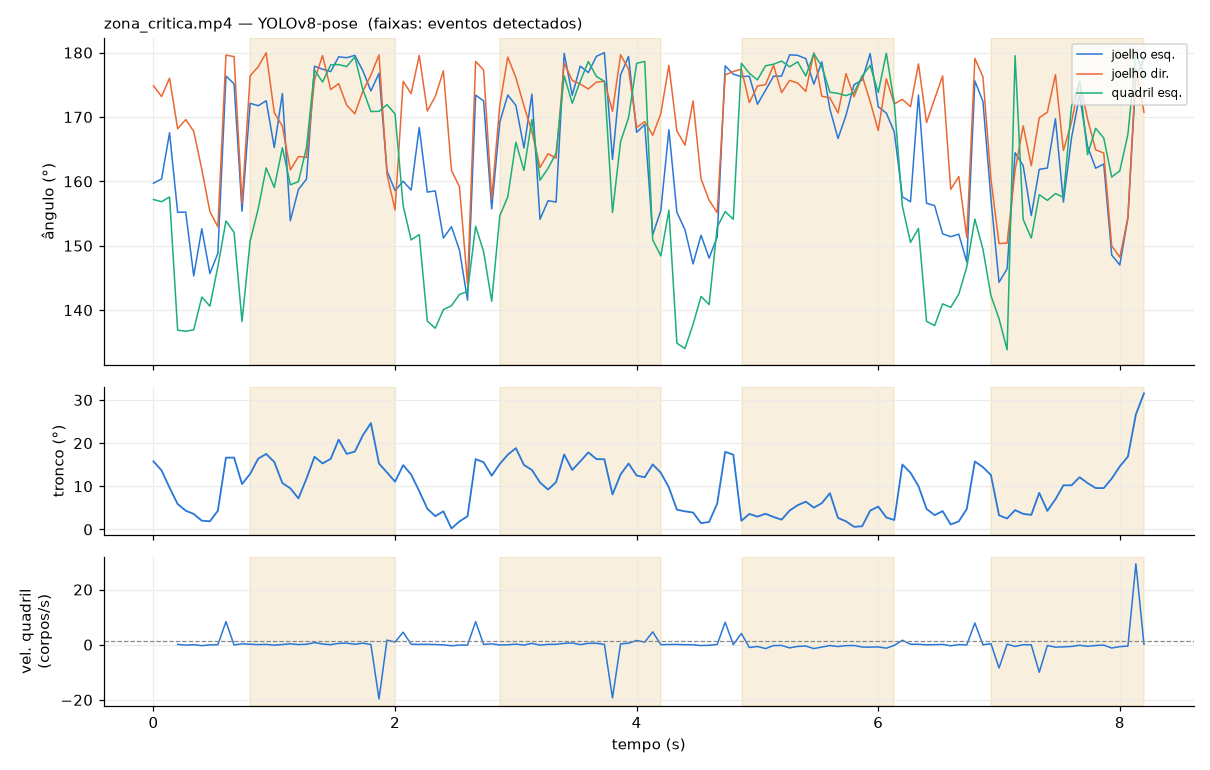

In [18]:
res_zone = run_video("zona_critica.mp4")           # área restrita com limite de 2 pessoas

Para analisar um vídeo seu, informe o caminho e o perfil (`agachamento`, `sentar_levantar`, `elevacao_braco`, `flexao_cotovelo` ou `None`):

In [19]:
MEU_VIDEO, PERFIL = "", None
if MEU_VIDEO:
    res = analyzer.analyze(MEU_VIDEO, "teste", PERFIL, ROOT / "outputs" / "video")
    print(res.summary); display(Image(res.plot_path, width=900)); show_video(res.annotated_path)

## 9. Dados reais — PhysioNet BIDMC (pacientes de UTI, 1 Hz)

In [20]:
from medmonitor.data.physionet import load_bidmc, physionet_config

pcfg = physionet_config(cfg)
for rec in (13, 14, 49):
    df = load_bidmc(rec, ROOT / "data" / "physionet")
    r = detect_vitals_anomalies(df, pcfg)
    for a in r.alerts:
        print(f"BIDMC{rec:02d} [{a.severity.name}] {a.timestamp[11:19]} {a.title}: {a.description}")
plot_vitals(detect_vitals_anomalies(load_bidmc(14, ROOT / "data" / "physionet"), pcfg).frame, "BIDMC14 — dado real")

BIDMC13 [WARNING] 08:00:53 Bradipneia: FR 0.0 irpm (basal 8.0). NEWS2 máx. 3 (risco baixo-médio), duração 1.4 min.


BIDMC14 [WARNING] 08:07:34 Taquipneia: FR 34.0 irpm (basal 17.0). NEWS2 máx. 4 (risco baixo-médio), duração 1.3 min.


BIDMC49 [WARNING] 08:03:40 Dessaturação: SpO2 85.0 % (basal 85.0). NEWS2 máx. 3 (risco baixo-médio), duração 1.2 min.
BIDMC49 [WARNING] 08:05:05 Dessaturação: SpO2 86.0 % (basal 85.0). NEWS2 máx. 3 (risco baixo-médio), duração 1.8 min.
BIDMC49 [WARNING] 08:07:24 Dessaturação: SpO2 86.0 % (basal 85.0). NEWS2 máx. 3 (risco baixo-médio), duração 1.3 min.


## 10. Fusão multimodal e alertas à equipe

O pipeline completo reúne todas as modalidades por paciente, calcula o **risco fundido** (noisy-OR ponderado) e aplica **7 regras de correlação temporal** que geram alertas que nenhuma fonte isolada geraria — por exemplo, *aumento de opioide → bradipneia* ou *arritmia + fala disártrica → suspeita de AVC*.

In [21]:
from medmonitor.pipeline import run_pipeline

results = run_pipeline(cfg, quiet=True)   # reaproveita os vídeos já processados acima
pd.DataFrame([{"paciente": p["patient_id"], "cenário": p.get("cenario"), "risco": p["risk"], "nível": p["level"],
               **p["modality_scores"], "alertas de fusão": len(p["correlations"])} for p in results["patients"]])

,paciente,cenário,risco,nível,vitals,movement,prescription,alertas de fusão,audio,video
0,P002,Sepse de foco pulmonar,1.000,alto,1.000,0.6,1.000,2,NaN,NaN
1,P003,Pós-operatório abdominal em analgesia com opioide,0.987,alto,0.939,0.0,0.667,2,0.92,NaN
2,P005,Pós-operatório de artroplastia de quadril,0.975,alto,0.606,1.0,0.667,3,0.85,0.50
3,P004,Fibrilação atrial paroxística,0.937,alto,0.644,0.0,1.000,1,0.80,NaN
4,SALA-01,NaN,0.700,moderado,NaN,NaN,NaN,0,NaN,1.00
5,P001,Controle estável,0.215,baixo,0.000,0.0,0.000,0,0.07,0.25


In [22]:
from medmonitor.alerts import load_alerts

fused = [a for a in load_alerts(ROOT / cfg["paths"]["alerts_log"]) if a.modality == "fusion"]
for a in sorted(fused, key=lambda a: a.timestamp):
    display(Markdown(f"**{'🔴' if a.severity.name == 'CRITICAL' else '🟠'} {a.timestamp[5:16].replace('T', ' ')} · "
                     f"{a.patient_id} · {a.title}**  \n{a.description}  \n*Evidências:* "
                     + "; ".join(f"{k}: {v}" for k, v in a.evidence.items())
                     + f"  \n*Conduta sugerida:* {a.recommended_action}"))
print(results["alerts"])

**🟠 10-28 15:00 · P005 · Risco elevado de queda (funcional + fadiga/imobilidade)**  
Execução motora alterada (repetições com amplitude incompleta) e imobilidade prolongada no leito.  
*Evidências:* video@15:00: Repetições com amplitude incompleta; movement@10:00: Imobilidade prolongada no leito  
*Conduta sugerida:* Implementar medidas de prevenção de quedas e reavaliar fisioterapia.

**🟠 10-28 19:00 · P002 · Alteração de alta vigilância após evento agudo (heparina)**  
Prescrição atípica: heparina (alta vigilância) às 19:00, taquicardia + hipotensão + taquipneia + febre às 18:18.  
*Evidências:* vitals@18:18: Taquicardia + Hipotensão + Taquipneia + Febre; prescription@19:00: Prescrição atípica: heparina (alta vigilância)  
*Conduta sugerida:* Confirmar indicação com o médico assistente antes de administrar.

**🔴 10-28 22:17 · P003 · Suspeita de depressão respiratória induzida por opioide/sedativo**  
morfina alterado às 21:00; bradicardia + hipotensão + dessaturação + bradipneia às 22:17.  
*Evidências:* prescription@21:00: Prescrição atípica: morfina (alta vigilância); vitals@22:17: Bradicardia + Hipotensão + Dessaturação + Bradipneia  
*Conduta sugerida:* Suspender/reduzir opioide e sedativo, considerar naloxona, monitorização contínua de SpO2/FR.

**🔴 10-28 22:40 · P003 · Insuficiência respiratória confirmada por voz e sinais vitais**  
Padrão de fala com dispneia (22:40) e bradicardia + hipotensão + dessaturação + bradipneia (22:17).  
*Evidências:* audio@22:40: Padrão de fala sugestivo de dificuldade respiratória; vitals@22:17: Bradicardia + Hipotensão + Dessaturação + Bradipneia  
*Conduta sugerida:* Avaliação médica imediata, gasometria arterial, suporte ventilatório conforme necessidade.

**🔴 10-29 01:03 · P002 · Suspeita de sepse com delirium (alteração do nível de consciência)**  
Taquicardia + Hipotensão + Taquipneia + Febre às 18:18 e agitação noturna às 01:03.  
*Evidências:* vitals@18:18: Taquicardia + Hipotensão + Taquipneia + Febre; movement@01:03: Agitação noturna  
*Conduta sugerida:* Abrir protocolo de sepse (lactato, culturas, antibiótico na 1ª hora) e avaliar CAM-ICU.

**🔴 10-29 03:03 · P005 · Queda confirmada por múltiplas fontes**  
Evidências: movement, video, vitals.  
*Evidências:* movement@03:00: Possível queda / saída do leito; video@02:59: Queda detectada; vitals@03:03: Taquicardia + Hipertensão + Taquipneia  
*Conduta sugerida:* Avaliar trauma (incluindo TCE), notificar evento adverso e revisar plano de prevenção de quedas.

**🔴 10-29 03:10 · P004 · Suspeita de AVC cardioembólico (arritmia + disartria)**  
Taquicardia às 02:04 e fala disártrica às 03:10.  
*Evidências:* vitals@02:04: Taquicardia; audio@03:10: Padrão de fala sugestivo de disartria  
*Conduta sugerida:* Acionar protocolo de AVC (código AVC), TC de crânio, avaliar janela para trombólise.

**🟠 10-29 03:30 · P005 · Alteração de alta vigilância após evento agudo (insulina)**  
Prescrição atípica: insulina (alta vigilância) às 03:30, possível queda / saída do leito às 03:00.  
*Evidências:* movement@03:00: Possível queda / saída do leito; prescription@03:30: Prescrição atípica: insulina (alta vigilância)  
*Conduta sugerida:* Confirmar indicação com o médico assistente antes de administrar.

{'generated': 40, 'dispatched': 37, 'suppressed': 3, 'by_severity': {'WARNING': 19, 'CRITICAL': 15, 'INFO': 3}, 'by_modality': {'vitals': 10, 'fusion': 8, 'prescription': 7, 'audio': 5, 'video': 4, 'movement': 3}}


In [23]:
# Relatório completo gerado pelo pipeline (tabelas + figuras em outputs/)
display(Markdown((ROOT / "outputs" / "relatorio_resultados.md").read_text().split("## 3.")[0]))

# Relatório de resultados — MedMonitor

Execução em 29/10/2026 13:34. Azure Speech: **fallback local** · Azure Language: **fallback local**.

## 1. Risco multimodal por paciente

![risco](figures/risk.png)

| Paciente | Cenário | Risco | Nível | Vitais | Prescr. | Movim. | Áudio | Vídeo | Alertas críticos |
|---|---|---|---|---|---|---|---|---|---|
| P002 | Sepse de foco pulmonar | 1.0 | alto | 1.0 | 1.0 | 0.6 |  |  | 3 |
| P003 | Pós-operatório abdominal em analgesia com opioide | 0.987 | alto | 0.939 | 0.667 | 0.0 | 0.92 |  | 5 |
| P005 | Pós-operatório de artroplastia de quadril | 0.975 | alto | 0.606 | 0.667 | 1.0 | 0.85 | 0.5 | 4 |
| P004 | Fibrilação atrial paroxística | 0.937 | alto | 0.644 | 1.0 | 0.0 | 0.8 |  | 3 |
| SALA-01 |  | 0.7 | moderado |  |  |  |  | 1.0 | 0 |
| P001 | Controle estável | 0.215 | baixo | 0.0 | 0.0 | 0.0 | 0.07 | 0.25 | 0 |

## 2. Alertas de fusão (correlação entre modalidades)

| Horário | Paciente | Severidade | Alerta | Evidências |
|---|---|---|---|---|
| 10-29 01:03 | P002 | CRITICAL | Suspeita de sepse com delirium (alteração do nível de consciência) | vitals@18:18: Taquicardia + Hipotensão + Taquipneia + Febre; movement@01:03: Agitação noturna |
| 10-28 19:00 | P002 | WARNING | Alteração de alta vigilância após evento agudo (heparina) | vitals@18:18: Taquicardia + Hipotensão + Taquipneia + Febre; prescription@19:00: Prescrição atípica: heparina (alta vigilância) |
| 10-28 22:17 | P003 | CRITICAL | Suspeita de depressão respiratória induzida por opioide/sedativo | prescription@21:00: Prescrição atípica: morfina (alta vigilância); vitals@22:17: Bradicardia + Hipotensão + Dessaturação + Bradipneia |
| 10-28 22:40 | P003 | CRITICAL | Insuficiência respiratória confirmada por voz e sinais vitais | audio@22:40: Padrão de fala sugestivo de dificuldade respiratória; vitals@22:17: Bradicardia + Hipotensão + Dessaturação + Bradipneia |
| 10-29 03:03 | P005 | CRITICAL | Queda confirmada por múltiplas fontes | movement@03:00: Possível queda / saída do leito; video@02:59: Queda detectada; vitals@03:03: Taquicardia + Hipertensão + Taquipneia |
| 10-28 15:00 | P005 | WARNING | Risco elevado de queda (funcional + fadiga/imobilidade) | video@15:00: Repetições com amplitude incompleta; movement@10:00: Imobilidade prolongada no leito |
| 10-29 03:30 | P005 | WARNING | Alteração de alta vigilância após evento agudo (insulina) | movement@03:00: Possível queda / saída do leito; prescription@03:30: Prescrição atípica: insulina (alta vigilância) |
| 10-29 03:10 | P004 | CRITICAL | Suspeita de AVC cardioembólico (arritmia + disartria) | vitals@02:04: Taquicardia; audio@03:10: Padrão de fala sugestivo de disartria |

Total: 40 alertas gerados, 37 despachados, 3 suprimidos pelo cooldown. Por severidade: {'WARNING': 19, 'CRITICAL': 15, 'INFO': 3}. Por modalidade: {'vitals': 10, 'fusion': 8, 'prescription': 7, 'audio': 5, 'video': 4, 'movement': 3}.



---
**Próximos passos:** a interface da equipe médica é o aplicativo desktop (`python main.py gui`), e o relatório técnico está em `docs/RELATORIO_TECNICO.md`.

> Ferramenta de apoio à decisão clínica. Dados de pacientes sintéticos; os achados não substituem avaliação profissional.